In [2]:
pip install kagglehub requests pandas numpy opencv-python scikit-image scikit-learn pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import subprocess
import sys

def _ensure_package(pkg_name, import_name=None):
    import_name = import_name or pkg_name
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])

_ensure_package("kagglehub")

d:\PythonProjects\MTEI\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import os
import time
import gc
from datetime import datetime
from collections import Counter

import kagglehub
import requests
import pandas as pd
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split

STAGE 1 — RAW DATA ACQUISITION

In [5]:
# 1a. Crop Recommendation Dataset (soil stats source)
crop_path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")
crop_df_raw = pd.read_csv(f"{crop_path}/Crop_recommendation.csv")
print(f"[Stage 1a] Crop Recommendation Dataset loaded (raw): {crop_df_raw.shape[0]} rows, "
      f"{crop_df_raw['label'].nunique()} crops")

print("\n===== Preview: Crop Recommendation Dataset (raw) =====")
print(crop_df_raw.head())
print(crop_df_raw.describe())
print("Crops:", crop_df_raw['label'].unique())


[Stage 1a] Crop Recommendation Dataset loaded (raw): 2200 rows, 22 crops

===== Preview: Crop Recommendation Dataset (raw) =====
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
                 N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.063749    22.263812   
min       0.000000     5.000000     5.000000     8.825675    14.258040   
25%      21.000000    28.000000    20.000000    22.769375    60.261953   
50%      37.000000    51.000000

In [7]:
# 1b. Leaf disease image dataset
img_path2 = kagglehub.dataset_download("jawadali1045/20k-multi-class-crop-disease-images")
train_path = os.path.join(img_path2, "Train")
val_path = os.path.join(img_path2, "Validation")
print(f"[Stage 1b] Image dataset downloaded: {img_path2}")

[Stage 1b] Image dataset downloaded: C:\Users\91979\.cache\kagglehub\datasets\jawadali1045\20k-multi-class-crop-disease-images\versions\1


In [8]:
print("\n===== Preview: Image Dataset Structure =====")
print("Train classes:", os.listdir(train_path))
print("Validation classes:", os.listdir(val_path))


===== Preview: Image Dataset Structure =====
Train classes: ['American Bollworm on Cotton', 'Anthracnose on Cotton', 'Army worm', 'bacterial_blight in Cotton', 'Becterial Blight in Rice', 'bollrot on Cotton', 'bollworm on Cotton', 'Brownspot', 'Common_Rust', 'Cotton Aphid', 'cotton mealy bug', 'cotton whitefly', 'Flag Smut', 'Gray_Leaf_Spot', 'Healthy cotton', 'Healthy Maize', 'Healthy Wheat', 'Leaf Curl', 'Leaf smut', 'maize ear rot', 'maize fall armyworm', 'maize stem borer', 'Mosaic sugarcane', 'pink bollworm in cotton', 'red cotton bug', 'RedRot sugarcane', 'RedRust sugarcane', 'Rice Blast', 'Sugarcane Healthy', 'thirps on  cotton', 'Tungro', 'Wheat aphid', 'Wheat black rust', 'Wheat Brown leaf Rust', 'Wheat leaf blight', 'Wheat mite', 'Wheat powdery mildew', 'Wheat scab', 'Wheat Stem fly', 'Wheat___Yellow_Rust', 'Wilt', 'Yellow Rust Sugarcane']
Validation classes: ['American Bollworm on Cotton', 'Anthracnose on Cotton', 'Army worm', 'Bacterial Blight in cotton', 'Becterial Blight

In [9]:
# 1c. NASA POWER weather (real-time API, fetched per location in Stage 3)
def fetch_nasa_power_hourly(lat, lon, start, end):
    url = "https://power.larc.nasa.gov/api/temporal/hourly/point"
    params = {
        "parameters": "T2M,RH2M,PRECTOTCORR",
        "community": "AG",
        "latitude": lat, "longitude": lon,
        "start": start, "end": end,
        "format": "JSON",
    }
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()["properties"]["parameter"]
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d%H")
    return df.reset_index().rename(columns={"index": "datetime"})


def fetch_nasa_power_hourly_chunked(lat, lon, start, end, chunk_days=180, retries=3):
    """Fetch in ~6-month chunks to avoid timeouts on multi-year hourly pulls."""
    all_chunks = []
    start_dt = pd.to_datetime(start, format="%Y%m%d")
    end_dt = pd.to_datetime(end, format="%Y%m%d")
    current = start_dt

    while current <= end_dt:
        chunk_end = min(current + pd.Timedelta(days=chunk_days), end_dt)
        s, e = current.strftime("%Y%m%d"), chunk_end.strftime("%Y%m%d")
        print(f"  Fetching {s} to {e}...")
        for attempt in range(retries):
            try:
                chunk_df = fetch_nasa_power_hourly(lat, lon, s, e)
                all_chunks.append(chunk_df)
                break
            except Exception as err:
                print(f"    retry {attempt+1}/{retries} failed: {err}")
                time.sleep(3)
        current = chunk_end + pd.Timedelta(days=1)

    return pd.concat(all_chunks, ignore_index=True)


print("[Stage 1c] NASA POWER fetch functions ready (called per-location in Stage 3)")

print("\n===== Preview: NASA POWER Weather Data (2023 - present) =====")
today_str = datetime.now().strftime("%Y%m%d")
sample_weather = fetch_nasa_power_hourly_chunked(10.79, 79.14, "20230101", today_str)
print(sample_weather.head())
print("Date range:", sample_weather['datetime'].min(), "to", sample_weather['datetime'].max())
print("Total rows:", len(sample_weather))

[Stage 1c] NASA POWER fetch functions ready (called per-location in Stage 3)

===== Preview: NASA POWER Weather Data (2023 - present) =====
  Fetching 20230101 to 20230630...
  Fetching 20230701 to 20231228...
  Fetching 20231229 to 20240626...
  Fetching 20240627 to 20241224...
  Fetching 20241225 to 20250623...
  Fetching 20250624 to 20251221...
  Fetching 20251222 to 20260620...
  Fetching 20260621 to 20260930...
             datetime    T2M   RH2M  PRECTOTCORR
0 2023-01-01 00:00:00  20.94  100.0          0.0
1 2023-01-01 01:00:00  20.71  100.0          0.0
2 2023-01-01 02:00:00  20.55  100.0          0.0
3 2023-01-01 03:00:00  20.42  100.0          0.0
4 2023-01-01 04:00:00  20.26  100.0          0.0
Date range: 2023-01-01 00:00:00 to 2026-09-30 23:00:00
Total rows: 32856


STAGE 2 — DATA CLEANING

In [10]:
def clean_crop_df(df: pd.DataFrame) -> pd.DataFrame:
    """Drop duplicates, drop rows missing required fields, then remove
    outliers PER CROP using the IQR rule (per-crop, not global, since
    rice and cotton have naturally different normal N/P/K/pH ranges)."""
    before = len(df)
    df = df.drop_duplicates()

    required_cols = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"]
    df = df.dropna(subset=required_cols)

    cleaned_parts = []
    numeric_cols = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
    for crop, group in df.groupby("label"):
        g = group.copy()
        for col in numeric_cols:
            q1, q3 = g[col].quantile(0.25), g[col].quantile(0.75)
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            g = g[(g[col] >= lower) & (g[col] <= upper)]
        cleaned_parts.append(g)

    df_clean = pd.concat(cleaned_parts, ignore_index=True)
    print(f"[Clean] crop_df: {before} -> {len(df_clean)} rows "
          f"({before - len(df_clean)} removed: duplicates/missing/outliers)")
    return df_clean


def clean_weather_df(df: pd.DataFrame) -> pd.DataFrame:
    """Time-series-aware cleaning: dedupe timestamps, convert NASA's
    -999 sentinel to NaN, interpolate along time (never drop hours,
    since Stage 6 needs continuous 24h sequences), clip impossible
    values."""
    before = len(df)
    df = df.sort_values("datetime").drop_duplicates(subset="datetime").reset_index(drop=True)
    df = df.replace(-999, np.nan).replace(-999.0, np.nan)

    for col in ["T2M", "RH2M", "PRECTOTCORR"]:
        if col in df.columns:
            df[col] = df[col].interpolate(method="linear", limit_direction="both")

    if "RH2M" in df.columns:
        df["RH2M"] = df["RH2M"].clip(0, 100)
    if "PRECTOTCORR" in df.columns:
        df["PRECTOTCORR"] = df["PRECTOTCORR"].clip(lower=0)

    print(f"[Clean] weather df: {before} -> {len(df)} rows "
          f"(duplicates removed, missing interpolated, out-of-range values clipped)")
    return df


crop_df = clean_crop_df(crop_df_raw)

[Clean] crop_df: 2200 -> 2200 rows (0 removed: duplicates/missing/outliers)


In [11]:
# 2b. Clean/validate the image class labels
folder_to_crop = {
    # RICE (5 classes)
    "Rice Blast": "rice",
    "Becterial Blight in Rice": "rice",
    "Leaf smut": "rice",
    "Brownspot": "rice",
    "Tungro": "rice",

    # MAIZE (6 classes)
    "Common_Rust": "maize",
    "Gray_Leaf_Spot": "maize",
    "maize ear rot": "maize",
    "maize fall armyworm": "maize",
    "maize stem borer": "maize",
    "Healthy Maize": "maize",

    # COTTON (12 classes)
    "bollrot on Cotton": "cotton",
    "thirps on  cotton": "cotton",
    "bollworm on Cotton": "cotton",
    "cotton mealy bug": "cotton",
    "Healthy cotton": "cotton",
    "cotton whitefly": "cotton",
    "pink bollworm in cotton": "cotton",
    "red cotton bug": "cotton",
    "Anthracnose on Cotton": "cotton",
    "Cotton Aphid": "cotton",
    "American Bollworm on Cotton": "cotton",
    "bacterial_blight in Cotton": "cotton",

    # WHEAT - not in your 22-crop list, drop
    "Wheat leaf blight": None, "Healthy Wheat": None, "Flag Smut": None,
    "Wheat aphid": None, "Wheat scab": None, "Wheat powdery mildew": None,
    "Wheat Stem fly": None, "Wheat mite": None, "Wheat Brown leaf Rust": None,
    "Wheat black rust": None, "Wheat___Yellow_Rust": None,

    # SUGARCANE - not in your 22-crop list, drop
    "RedRust sugarcane": None, "Yellow Rust Sugarcane": None,
    "RedRot sugarcane": None, "Sugarcane Healthy": None, "Mosaic sugarcane": None,

    # RESOLVED per review: Army worm and Wilt are generic pest/stress
    # categories that appear predominantly in this dataset's maize
    # subfolders -> mapped to maize. Leaf Curl visually confirmed as a
    # cotton symptom -> mapped to cotton. Re-verify against your own
    # copy of the dataset before finalizing.
    "Army worm": "maize",
    "Wilt": "maize",
    "Leaf Curl": "cotton",
}

_NON_CROP_LIST_FOLDERS = (
    "Wheat leaf blight", "Healthy Wheat", "Flag Smut", "Wheat aphid", "Wheat scab",
    "Wheat powdery mildew", "Wheat Stem fly", "Wheat mite", "Wheat Brown leaf Rust",
    "Wheat black rust", "Wheat___Yellow_Rust", "RedRust sugarcane",
    "Yellow Rust Sugarcane", "RedRot sugarcane", "Sugarcane Healthy", "Mosaic sugarcane",
)


def split_unresolved_for_review(folder_to_crop_map: dict):
    resolved = {k: v for k, v in folder_to_crop_map.items() if v is not None}
    unresolved = [k for k, v in folder_to_crop_map.items()
                  if v is None and k not in _NON_CROP_LIST_FOLDERS]
    print(f"[Stage 2b] Resolved & usable: {len(resolved)} folders")
    print(f"[Stage 2b] Excluded (wheat/sugarcane, not in crop list): {len(_NON_CROP_LIST_FOLDERS)} folders")
    print(f"[Stage 2b] STILL NEEDS VISUAL REVIEW: {unresolved}")
    return resolved, unresolved


valid_folders, unresolved_folders = split_unresolved_for_review(folder_to_crop)
print(f"[Stage 2b] Usable image classes: {len(valid_folders)} / {len(folder_to_crop)}")
print(f"[Stage 2b] Crop distribution: {Counter(valid_folders.values())}")

[Stage 2b] Resolved & usable: 26 folders
[Stage 2b] Excluded (wheat/sugarcane, not in crop list): 16 folders
[Stage 2b] STILL NEEDS VISUAL REVIEW: []
[Stage 2b] Usable image classes: 26 / 42
[Stage 2b] Crop distribution: Counter({'cotton': 13, 'maize': 8, 'rice': 5})


STAGE 3-LEFT — Sensor/Weather path

In [12]:
def simulate_soil_moisture(df, field_capacity=35, initial=25, et_coeff=0.05):
    moisture = [initial]
    for i in range(1, len(df)):
        et_loss = et_coeff * df["T2M"].iloc[i]
        rain_gain = df["PRECTOTCORR"].iloc[i]
        new_m = np.clip(moisture[-1] - et_loss + rain_gain, 0, field_capacity)
        moisture.append(new_m)
    return moisture


TN_LOCATIONS = {
    "Thanjavur":  {"lat": 10.79, "lon": 79.14},
    "Coimbatore": {"lat": 11.00, "lon": 76.96},
    "Nilgiris":   {"lat": 11.41, "lon": 76.70},
    "Madurai":    {"lat": 9.93,  "lon": 78.12},
    "Vellore":    {"lat": 12.92, "lon": 79.13},
}
START_DATE = "20220101"
END_DATE = datetime.now().strftime("%Y%m%d")


def load_crop_reference_stats(crop_df_in):
    stats = {}
    for crop in crop_df_in['label'].unique():
        subset = crop_df_in[crop_df_in['label'] == crop]
        stats[crop] = {
            'N': (subset['N'].mean(), subset['N'].std()),
            'P': (subset['P'].mean(), subset['P'].std()),
            'K': (subset['K'].mean(), subset['K'].std()),
            'ph': (subset['ph'].mean(), subset['ph'].std()),
            'temperature': (subset['temperature'].mean(), subset['temperature'].std()),
            'humidity': (subset['humidity'].mean(), subset['humidity'].std()),
            'rainfall': (subset['rainfall'].mean(), subset['rainfall'].std()),
        }
    return stats


crop_stats = load_crop_reference_stats(crop_df)


def add_moving_averages(df: pd.DataFrame, group_cols=("crop", "location"),
                         windows=(3, 24)) -> pd.DataFrame:
    """Rolling-mean features per (crop, location) group so windows from
    one location don't bleed into another's rolling average."""
    df = df.sort_values("datetime").copy()
    base_cols = ["T2M", "RH2M", "PRECTOTCORR", "soil_moisture"]
    for col in base_cols:
        for w in windows:
            new_col = f"{col}_ma{w}h"
            df[new_col] = (
                df.groupby(list(group_cols))[col]
                  .transform(lambda s: s.rolling(window=w, min_periods=1).mean())
            )
    return df


def add_index_features(df: pd.DataFrame) -> pd.DataFrame:
    """Derived agronomic index features: THI (heat-stress index),
    aridity_index (dryness), npk_balance (deviation from a 4:2:1
    N:P:K reference ratio)."""
    df = df.copy()
    df["THI"] = df["T2M"] - (0.55 - 0.0055 * df["RH2M"]) * (df["T2M"] - 14.5)
    df["aridity_index"] = df["PRECTOTCORR"] / (df["T2M"].abs() + 1)

    if {"N", "P", "K"}.issubset(df.columns):
        target_ratio = np.array([4, 2, 1], dtype=float)
        target_ratio = target_ratio / target_ratio.sum()
        totals = (df["N"] + df["P"] + df["K"]).replace(0, np.nan)
        actual_ratio = np.stack([df["N"] / totals, df["P"] / totals, df["K"] / totals], axis=1)
        df["npk_balance"] = np.linalg.norm(actual_ratio - target_ratio, axis=1)
        df["npk_balance"] = df["npk_balance"].fillna(df["npk_balance"].median())
    return df


sensor_rows = []
rng = np.random.default_rng(42)

for loc_name, info in TN_LOCATIONS.items():
    print(f"[Stage 3-left] Fetching weather for {loc_name}...")
    weather = fetch_nasa_power_hourly_chunked(info["lat"], info["lon"], START_DATE, END_DATE)
    weather = clean_weather_df(weather)

    weather["soil_moisture"] = simulate_soil_moisture(weather)
    weather["location"] = loc_name

    for crop in crop_stats.keys():          # all 22 crops for the sensor-only heads
        stats = crop_stats[crop]
        df = weather.copy()
        n = len(df)
        df["N"] = rng.normal(stats['N'][0], stats['N'][1], n).clip(0, 150)
        df["P"] = rng.normal(stats['P'][0], stats['P'][1], n).clip(0, 150)
        df["K"] = rng.normal(stats['K'][0], stats['K'][1], n).clip(0, 210)
        df["pH"] = rng.normal(stats['ph'][0], stats['ph'][1], n).clip(3.0, 10.0)
        df["crop"] = crop
        sensor_rows.append(df)

sensor_df = pd.concat(sensor_rows, ignore_index=True)
print(f"[Stage 3-left] Sensor path complete: {sensor_df.shape[0]} rows, "
      f"{sensor_df['crop'].nunique()} crops x {len(TN_LOCATIONS)} locations")

sensor_df = add_moving_averages(sensor_df)
sensor_df = add_index_features(sensor_df)
# NOTE: min-max scaling is NO LONGER done here globally (that was Issue #2 -
# it leaked val/test statistics into the scaling and was never even wired
# into windowing). Scaling now happens per-group, train-fit-only, inside
# chronological_split_and_scale() below, AFTER the chronological split.
print(f"[Stage 3-left] Feature engineering applied. sensor_df now has "
      f"{sensor_df.shape[1]} columns.")

del sensor_rows
gc.collect()

[Stage 3-left] Fetching weather for Thanjavur...
  Fetching 20220101 to 20220630...
  Fetching 20220701 to 20221228...
  Fetching 20221229 to 20230627...
  Fetching 20230628 to 20231225...
  Fetching 20231226 to 20240623...
  Fetching 20240624 to 20241221...
  Fetching 20241222 to 20250620...
  Fetching 20250621 to 20251218...
  Fetching 20251219 to 20260617...
  Fetching 20260618 to 20260930...
[Clean] weather df: 41616 -> 41616 rows (duplicates removed, missing interpolated, out-of-range values clipped)
[Stage 3-left] Fetching weather for Coimbatore...
  Fetching 20220101 to 20220630...
  Fetching 20220701 to 20221228...
  Fetching 20221229 to 20230627...
  Fetching 20230628 to 20231225...
  Fetching 20231226 to 20240623...
  Fetching 20240624 to 20241221...
  Fetching 20241222 to 20250620...
  Fetching 20250621 to 20251218...
  Fetching 20251219 to 20260617...
  Fetching 20260618 to 20260930...
[Clean] weather df: 41616 -> 41616 rows (duplicates removed, missing interpolated, out-of

0

STAGE 3-RIGHT — Image path: resize, denoise, color-normalize, augment

In [13]:
IMG_SIZE = 128


def denoise_image(img_uint8: np.ndarray) -> np.ndarray:
    return cv2.fastNlMeansDenoisingColored(img_uint8, None, h=6, hColor=6,
                                            templateWindowSize=7, searchWindowSize=21)


def normalize_color(img_uint8: np.ndarray) -> np.ndarray:
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge([l_eq, a, b])
    return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)


def augment_image(img_uint8: np.ndarray, img_rng: np.random.Generator) -> np.ndarray:
    out = img_uint8.copy()
    if img_rng.random() < 0.5:
        out = cv2.flip(out, 1)
    if img_rng.random() < 0.3:
        out = cv2.flip(out, 0)
    angle = img_rng.uniform(-15, 15)
    h, w = out.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    out = cv2.warpAffine(out, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    brightness = img_rng.uniform(0.85, 1.15)
    out = np.clip(out.astype(np.float32) * brightness, 0, 255).astype(np.uint8)
    return out


def load_and_preprocess_images(train_path_in, val_path_in, valid_folders_in, img_size=128,
                                augment_train=True, seed=42, denoise=True, log_every=1000):
    img_rng = np.random.default_rng(seed)

    file_list = []
    for split_name, split_path in [("Train", train_path_in), ("Validation", val_path_in)]:
        for folder_name, crop in valid_folders_in.items():
            folder_full_path = os.path.join(split_path, folder_name)
            if not os.path.isdir(folder_full_path):
                continue
            for fname in os.listdir(folder_full_path):
                file_list.append((os.path.join(folder_full_path, fname), split_name, crop, folder_name))

    n_total = len(file_list)
    print(f"[Stage 3-right] Found {n_total} candidate images. Processing...")

    images = np.empty((n_total, img_size, img_size, 3), dtype=np.float32)
    crops, disease_labels, splits = [], [], []
    kept = 0

    for i, (fpath, split_name, crop, folder_name) in enumerate(file_list):
        raw_img = cv2.imread(fpath)
        if raw_img is None:
            continue

        proc = cv2.resize(raw_img, (img_size, img_size))

        if denoise:
            proc = denoise_image(proc)
        proc = normalize_color(proc)

        if augment_train and split_name == "Train" and img_rng.random() < 0.5:
            proc = augment_image(proc, img_rng)

        images[kept] = (proc / 255.0).astype(np.float32)
        crops.append(crop)
        disease_labels.append(folder_name)
        splits.append(split_name)
        kept += 1

        if (i + 1) % log_every == 0:
            print(f"  ...{i + 1}/{n_total} images scanned, {kept} kept")

    images = images[:kept]
    print(f"[Stage 3-right] Done: {kept}/{n_total} images kept.")
    return images, np.array(crops), np.array(disease_labels), np.array(splits)


X_images, image_crops, image_disease_labels, image_splits = load_and_preprocess_images(
    train_path, val_path, valid_folders, IMG_SIZE
)
print(f"[Stage 3-right] Images loaded & preprocessed: {len(X_images)}, shape {X_images[0].shape}")
print(f"[Stage 3-right] Crop distribution: {Counter(image_crops)}")
print(f"[Stage 3-right] Split distribution: {Counter(image_splits)}")

[Stage 3-right] Found 13736 candidate images. Processing...
  ...1000/13736 images scanned, 1000 kept
  ...2000/13736 images scanned, 2000 kept
  ...3000/13736 images scanned, 3000 kept
  ...4000/13736 images scanned, 4000 kept
  ...5000/13736 images scanned, 5000 kept
  ...6000/13736 images scanned, 6000 kept
  ...7000/13736 images scanned, 7000 kept
  ...8000/13736 images scanned, 8000 kept
  ...9000/13736 images scanned, 9000 kept
  ...10000/13736 images scanned, 10000 kept
  ...11000/13736 images scanned, 11000 kept
  ...12000/13736 images scanned, 12000 kept
  ...13000/13736 images scanned, 13000 kept
[Stage 3-right] Done: 13736/13736 images kept.
[Stage 3-right] Images loaded & preprocessed: 13736, shape (128, 128, 3)
[Stage 3-right] Crop distribution: Counter({np.str_('rice'): 6112, np.str_('maize'): 5053, np.str_('cotton'): 2571})
[Stage 3-right] Split distribution: Counter({np.str_('Train'): 11594, np.str_('Validation'): 2142})


STAGE 4 — HANDCRAFTED FEATURE EXTRACTION (image path only)

In [14]:
def extract_handcrafted_features(img_float):
    """img_float: normalized [0,1] BGR image, shape (H, W, 3).
    Returns 9 features: leaf_area, spot_area_ratio, spot_count,
    h_mean, s_mean, v_mean, glcm_contrast, glcm_homogeneity, glcm_energy.

    NOTE vs. original: spot detection is now a SEPARATE threshold step
    (dark/low-value regions within the leaf mask), not reused from the
    leaf-vs-background Otsu mask, so 'spot density' is a genuinely
    distinct feature from 'leaf area' as claimed in the paper's abstract."""
    img_uint8 = (img_float * 255).astype(np.uint8)
    gray = cv2.cvtColor(img_uint8, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img_uint8, cv2.COLOR_BGR2HSV)

    # Leaf segmentation (foreground vs background)
    _, leaf_mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    leaf_area = float(np.sum(leaf_mask > 0))

    # Spot/lesion detection: dark, low-value regions WITHIN the leaf mask
    v_channel = hsv[:, :, 2]
    leaf_pixels_v = v_channel[leaf_mask > 0]
    if leaf_pixels_v.size > 0:
        v_thresh = np.percentile(leaf_pixels_v, 35)
    else:
        v_thresh = 0
    spot_candidate = ((v_channel < v_thresh) & (leaf_mask > 0)).astype(np.uint8) * 255
    n_labels, _, stats_cc, _ = cv2.connectedComponentsWithStats(spot_candidate, connectivity=8)
    spot_count = int(np.sum(stats_cc[1:, cv2.CC_STAT_AREA] > 5)) if n_labels > 1 else 0
    spot_area = float(np.sum(spot_candidate > 0))
    spot_area_ratio = spot_area / leaf_area if leaf_area > 0 else 0.0

    h_mean, s_mean, v_mean = hsv[:, :, 0].mean(), hsv[:, :, 1].mean(), hsv[:, :, 2].mean()

    glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256,
                         symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]

    return [leaf_area, spot_area_ratio, spot_count,
            h_mean, s_mean, v_mean, contrast, homogeneity, energy]


X_handcrafted = np.array([extract_handcrafted_features(im) for im in X_images])
print(f"[Stage 4] Handcrafted features shape: {X_handcrafted.shape}  "
      f"(columns: leaf_area, spot_area_ratio, spot_count, h_mean, s_mean, v_mean, "
      f"glcm_contrast, glcm_homogeneity, glcm_energy)")

[Stage 4] Handcrafted features shape: (13736, 9)  (columns: leaf_area, spot_area_ratio, spot_count, h_mean, s_mean, v_mean, glcm_contrast, glcm_homogeneity, glcm_energy)


STAGE 5 — LABEL GENERATION

In [15]:
def label_irrigation(moisture, field_capacity=35):
    pct = moisture / field_capacity
    if pct > 0.7:
        return 0
    elif pct > 0.4:
        return 1
    return 2


def label_soil_health(pH, N, P, K, crop, crop_stats_dict):
    stats = crop_stats_dict[crop]
    ph_ok = (stats['ph'][0] - stats['ph'][1]) <= pH <= (stats['ph'][0] + stats['ph'][1])
    n_ok = N > (stats['N'][0] - stats['N'][1])
    p_ok = P > (stats['P'][0] - stats['P'][1])
    k_ok = K > (stats['K'][0] - stats['K'][1])
    return 0 if (ph_ok and n_ok and p_ok and k_ok) else 1


def label_climatic_stress(temp, crop, crop_stats_dict):
    stats = crop_stats_dict[crop]
    heat_thresh = stats['temperature'][0] + 2 * stats['temperature'][1]
    frost_thresh = stats['temperature'][0] - 2 * stats['temperature'][1]
    if temp > heat_thresh:
        return 0
    elif temp < frost_thresh:
        return 1
    return 2


def label_disease_risk(temp, humidity, rainfall, N, K, pH, crop, crop_stats_dict):
    stats = crop_stats_dict[crop]
    humidity_high = humidity > (stats['humidity'][0] + stats['humidity'][1])
    temp_in_range = abs(temp - stats['temperature'][0]) < stats['temperature'][1]
    ph_low, ph_high = stats['ph'][0] - stats['ph'][1], stats['ph'][0] + stats['ph'][1]
    weak_plant = (K < stats['K'][0] - stats['K'][1]) or (pH < ph_low or pH > ph_high)
    if humidity_high and temp_in_range and rainfall > 0:
        return 1
    elif weak_plant and humidity_high:
        return 1
    return 0


print("[Stage 5a] Generating sensor-path labels...")
sensor_df["irrigation_label"] = sensor_df["soil_moisture"].apply(label_irrigation)
sensor_df["health_label"] = sensor_df.apply(
    lambda r: label_soil_health(r['pH'], r['N'], r['P'], r['K'], r['crop'], crop_stats), axis=1)
sensor_df["stress_label"] = sensor_df.apply(
    lambda r: label_climatic_stress(r['T2M'], r['crop'], crop_stats), axis=1)
sensor_df["disease_risk_label"] = sensor_df.apply(
    lambda r: label_disease_risk(
        r['T2M'], r['RH2M'], r['PRECTOTCORR'], r['N'], r['K'], r['pH'], r['crop'], crop_stats
    ), axis=1)
print("[Stage 5a] Sensor labels done: irrigation, health, stress, disease_risk")
print(f"[Stage 5b] Image labels ready: {len(set(image_disease_labels))} disease classes")

[Stage 5a] Generating sensor-path labels...
[Stage 5a] Sensor labels done: irrigation, health, stress, disease_risk
[Stage 5b] Image labels ready: 26 disease classes


STAGE 6+7 (FIXED) — CHRONOLOGICAL SPLIT, TRAIN-FIT SCALING, THEN WINDOWING

In [16]:
# FIX #1: split each (crop, location) series chronologically into
# train/val/test BEFORE any window is built. A window is only ever
# constructed from rows that already belong to a single split, so no
# window can span a split boundary and no information leaks across sets.
#
# FIX #2: min-max scaling is fit ONLY on each group's train portion,
# then applied (not re-fit) to that group's val/test portion. The
# resulting _scaled columns ARE included in feature_cols below.

RAW_SCALE_COLS = ["T2M", "RH2M", "PRECTOTCORR", "soil_moisture", "N", "P", "K", "pH"]


def chronological_split_and_scale(df, group_cols=("crop", "location"),
                                   train_frac=0.70, val_frac=0.15):
    """Returns (train_df, val_df, test_df), each with _scaled columns
    added using min/max fit on that group's TRAIN portion only."""
    train_parts, val_parts, test_parts = [], [], []

    for (crop, location), group in df.groupby(list(group_cols)):
        g = group.sort_values("datetime").reset_index(drop=True)
        n = len(g)
        n_train = int(n * train_frac)
        n_val = int(n * val_frac)

        g_train = g.iloc[:n_train].copy()
        g_val = g.iloc[n_train:n_train + n_val].copy()
        g_test = g.iloc[n_train + n_val:].copy()

        # Fit scaler on TRAIN portion of this group only
        for col in RAW_SCALE_COLS:
            cmin, cmax = g_train[col].min(), g_train[col].max()
            denom = (cmax - cmin) if (cmax - cmin) != 0 else 1
            g_train[f"{col}_scaled"] = (g_train[col] - cmin) / denom
            g_val[f"{col}_scaled"] = ((g_val[col] - cmin) / denom).clip(0, 1)
            g_test[f"{col}_scaled"] = ((g_test[col] - cmin) / denom).clip(0, 1)

        train_parts.append(g_train)
        val_parts.append(g_val)
        test_parts.append(g_test)

    train_df_out = pd.concat(train_parts, ignore_index=True)
    val_df_out = pd.concat(val_parts, ignore_index=True)
    test_df_out = pd.concat(test_parts, ignore_index=True)

    print(f"[Split] Chronological per-group split: "
          f"train={len(train_df_out)}, val={len(val_df_out)}, test={len(test_df_out)} rows")
    return train_df_out, val_df_out, test_df_out


def build_windows_for_split(df, feature_cols, label_cols, window_size=24, step=6,
                             dtype=np.float32, log_every=200000):
    """Builds windows within a single already-split dataframe. Since df
    only contains rows from one split, no window can cross a split
    boundary - this is what actually fixes the leakage."""
    n_features = len(feature_cols)
    n_labels = len(label_cols)
    groups = list(df.groupby(["crop", "location"]))

    total_windows = 0
    for (crop, location), group in groups:
        n = len(group)
        total_windows += len(range(0, max(n - window_size, 0), step))

    X = np.empty((total_windows, window_size, n_features), dtype=dtype)
    y = np.empty((total_windows, n_labels), dtype=dtype)
    crop_names = np.empty(total_windows, dtype=object)

    idx = 0
    for (crop, location), group in groups:
        group = group.sort_values("datetime").reset_index(drop=True)
        feat_arr = group[feature_cols].values.astype(dtype)
        label_arr = group[label_cols].values.astype(dtype)
        n = len(group)

        for i in range(0, max(n - window_size, 0), step):
            X[idx] = feat_arr[i:i + window_size]
            y[idx] = label_arr[i + window_size - 1]
            crop_names[idx] = crop
            idx += 1
            if idx % log_every == 0:
                print(f"    ...{idx}/{total_windows} windows built")

    assert idx == total_windows, f"Mismatch: built {idx} windows, expected {total_windows}"

    unique_crops = sorted(set(crop_names)) if total_windows > 0 else []
    crop_to_idx = {c: i for i, c in enumerate(unique_crops)}
    crop_onehot = np.zeros((total_windows, len(unique_crops)), dtype=dtype)
    for i, c in enumerate(crop_names):
        crop_onehot[i, crop_to_idx[c]] = 1.0

    return X, crop_onehot, y, unique_crops


print("[Stage 6+7] Splitting sensor_df chronologically per (crop, location)...")
train_df, val_df, test_df = chronological_split_and_scale(sensor_df)

FEATURE_COLS = [
    # raw
    "T2M", "RH2M", "PRECTOTCORR", "soil_moisture", "N", "P", "K", "pH",
    # engineered (moving averages + agronomic indices)
    "T2M_ma3h", "T2M_ma24h", "RH2M_ma3h", "RH2M_ma24h",
    "PRECTOTCORR_ma3h", "PRECTOTCORR_ma24h",
    "soil_moisture_ma3h", "soil_moisture_ma24h",
    "THI", "aridity_index", "npk_balance",
    # FIX #2: scaled columns now actually used
    "T2M_scaled", "RH2M_scaled", "PRECTOTCORR_scaled", "soil_moisture_scaled",
    "N_scaled", "P_scaled", "K_scaled", "pH_scaled",
]
LABEL_COLS = ["irrigation_label", "health_label", "stress_label", "disease_risk_label"]

print("[Stage 6+7] Building windows per split (train)...")
X_sensor_train, oh_train, y_sensor_train, crop_list_train = build_windows_for_split(
    train_df, FEATURE_COLS, LABEL_COLS)
print(f"  -> X_sensor_train: {X_sensor_train.shape}")

print("[Stage 6+7] Building windows per split (val)...")
X_sensor_val, oh_val, y_sensor_val, _ = build_windows_for_split(
    val_df, FEATURE_COLS, LABEL_COLS)
print(f"  -> X_sensor_val: {X_sensor_val.shape}")

print("[Stage 6+7] Building windows per split (test)...")
X_sensor_test, oh_test, y_sensor_test, _ = build_windows_for_split(
    test_df, FEATURE_COLS, LABEL_COLS)
print(f"  -> X_sensor_test: {X_sensor_test.shape}")

print("[Stage 6+7] DONE - no window spans a split boundary (fixes Issue #1), "
      "scaled features included (fixes Issue #2).")

[Stage 6+7] Splitting sensor_df chronologically per (crop, location)...
[Split] Chronological per-group split: train=3204410, val=686620, test=686730 rows
[Stage 6+7] Building windows per split (train)...
    ...200000/533720 windows built
    ...400000/533720 windows built
  -> X_sensor_train: (533720, 24, 27)
[Stage 6+7] Building windows per split (val)...
  -> X_sensor_val: (114070, 24, 27)
[Stage 6+7] Building windows per split (test)...
  -> X_sensor_test: (114070, 24, 27)
[Stage 6+7] DONE - no window spans a split boundary (fixes Issue #1), scaled features included (fixes Issue #2).


7b. Image path split (independent samples, no sequence-leakage risk)

In [17]:
# random split remains appropriate here) ---
X_img_train, X_img_temp, hc_train, hc_temp, dislabel_train, dislabel_temp = train_test_split(
    X_images, X_handcrafted, image_disease_labels, test_size=0.30, random_state=42)
X_img_val, X_img_test, hc_val, hc_test, dislabel_val, dislabel_test = train_test_split(
    X_img_temp, hc_temp, dislabel_temp, test_size=0.5, random_state=42)

print(f"[Stage 7] Image split   -> train {X_img_train.shape[0]}, "
      f"val {X_img_val.shape[0]}, test {X_img_test.shape[0]}")

[Stage 7] Image split   -> train 9615, val 2060, test 2061


STAGE 8 — READY DATASET

In [20]:
np.savez(
    "mtei_ready_dataset.npz",
    # sensor path (leakage-safe: windows built after chronological split)
    X_sensor_train=X_sensor_train, X_sensor_val=X_sensor_val, X_sensor_test=X_sensor_test,
    y_sensor_train=y_sensor_train, y_sensor_val=y_sensor_val, y_sensor_test=y_sensor_test,
    crop_onehot_train=oh_train, crop_onehot_val=oh_val, crop_onehot_test=oh_test,
    # image path
    X_images_train=X_img_train, X_images_val=X_img_val, X_images_test=X_img_test,
    X_handcrafted_train=hc_train, X_handcrafted_val=hc_val, X_handcrafted_test=hc_test,
    disease_label_train=dislabel_train, disease_label_val=dislabel_val, disease_label_test=dislabel_test,
)
print("[Stage 8] Saved: mtei_ready_dataset.npz - Framework 1 pipeline complete (leakage-fixed).")

[Stage 8] Saved: mtei_ready_dataset.npz - Framework 1 pipeline complete (leakage-fixed).


In [19]:
import numpy as np
import pandas as pd
 
data = np.load("mtei_ready_dataset.npz", allow_pickle=True)

In [21]:
# TABLE 1 — Split sizes (sensor windows + images)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Sensor Windows": [
        data["X_sensor_train"].shape[0],
        data["X_sensor_val"].shape[0],
        data["X_sensor_test"].shape[0],
    ],
    "Images": [
        data["X_images_train"].shape[0],
        data["X_images_val"].shape[0],
        data["X_images_test"].shape[0],
    ],
})
 
print("TABLE 1: Dataset Split Sizes")
print(split_summary.to_string(index=False))
print()

TABLE 1: Dataset Split Sizes
     Split  Sensor Windows  Images
     Train          533720    9615
Validation          114070    2060
      Test          114070    2061



In [22]:
# TABLE 2 — Label distribution per head (train set)

label_names = {
    0: {"irrigation": "Low",   "health": "Stable",   "stress": "Heat",   "disease_risk": "Healthy"},
    1: {"irrigation": "Medium","health": "Critical",  "stress": "Frost",  "disease_risk": "At Risk"},
    2: {"irrigation": "High",  "health": None,        "stress": "Normal", "disease_risk": None},
}
 
head_names = ["irrigation", "health", "stress", "disease_risk"]
rows = []
 
for i, head in enumerate(head_names):
    vals, counts = np.unique(data["y_sensor_train"][:, i], return_counts=True)
    total = counts.sum()
    for v, c in zip(vals, counts):
        label_text = label_names.get(int(v), {}).get(head, f"class_{int(v)}")
        rows.append({
            "Head": head,
            "Class": label_text,
            "Count": int(c),
            "Percent": round(100 * c / total, 1),
        })
 
label_summary = pd.DataFrame(rows)
 
print("TABLE 2: Label Distribution per Head (Train Set)")
print(label_summary.to_string(index=False))
print()

TABLE 2: Label Distribution per Head (Train Set)
        Head    Class  Count  Percent
  irrigation      Low   1320      0.2
  irrigation   Medium   1958      0.4
  irrigation     High 530442     99.4
      health   Stable 217320     40.7
      health Critical 316400     59.3
      stress     Heat 135524     25.4
      stress    Frost 123899     23.2
      stress   Normal 274297     51.4
disease_risk  Healthy 379916     71.2
disease_risk  At Risk 153804     28.8



In [23]:
# TABLE 3 — Image dataset: disease class distribution

if "disease_label_train" in data:
    vals, counts = np.unique(data["disease_label_train"], return_counts=True)
    image_summary = pd.DataFrame({
        "Disease Class": vals,
        "Count (Train)": counts,
    }).sort_values("Count (Train)", ascending=False).reset_index(drop=True)
 
    print("TABLE 3: Disease Class Distribution (Train Images)")
    print(image_summary.to_string(index=False))
    print()

TABLE 3: Disease Class Distribution (Train Images)
              Disease Class  Count (Train)
                  Brownspot           1152
   Becterial Blight in Rice           1125
                 Rice Blast           1024
              Healthy Maize            979
                Common_Rust            941
                     Tungro            928
                       Wilt            585
             Gray_Leaf_Spot            420
             Healthy cotton            415
                  Leaf Curl            353
 bacterial_blight in Cotton            351
                  Army worm            298
               Cotton Aphid            232
        maize fall armyworm            128
           maize stem borer            112
           cotton mealy bug            109
              maize ear rot            102
             red cotton bug             81
            cotton whitefly             61
American Bollworm on Cotton             60
          thirps on  cotton             47
   

In [24]:
# TABLE 4 — Feature/shape summary

shape_summary = pd.DataFrame({
    "Array": ["X_sensor_train", "X_images_train", "X_handcrafted_train"],
    "Shape": [
        str(data["X_sensor_train"].shape),
        str(data["X_images_train"].shape),
        str(data["X_handcrafted_train"].shape),
    ],
})
 
print("TABLE 4: Array Shapes")
print(shape_summary.to_string(index=False))

TABLE 4: Array Shapes
              Array               Shape
     X_sensor_train    (533720, 24, 27)
     X_images_train (9615, 128, 128, 3)
X_handcrafted_train           (9615, 9)


In [25]:
pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


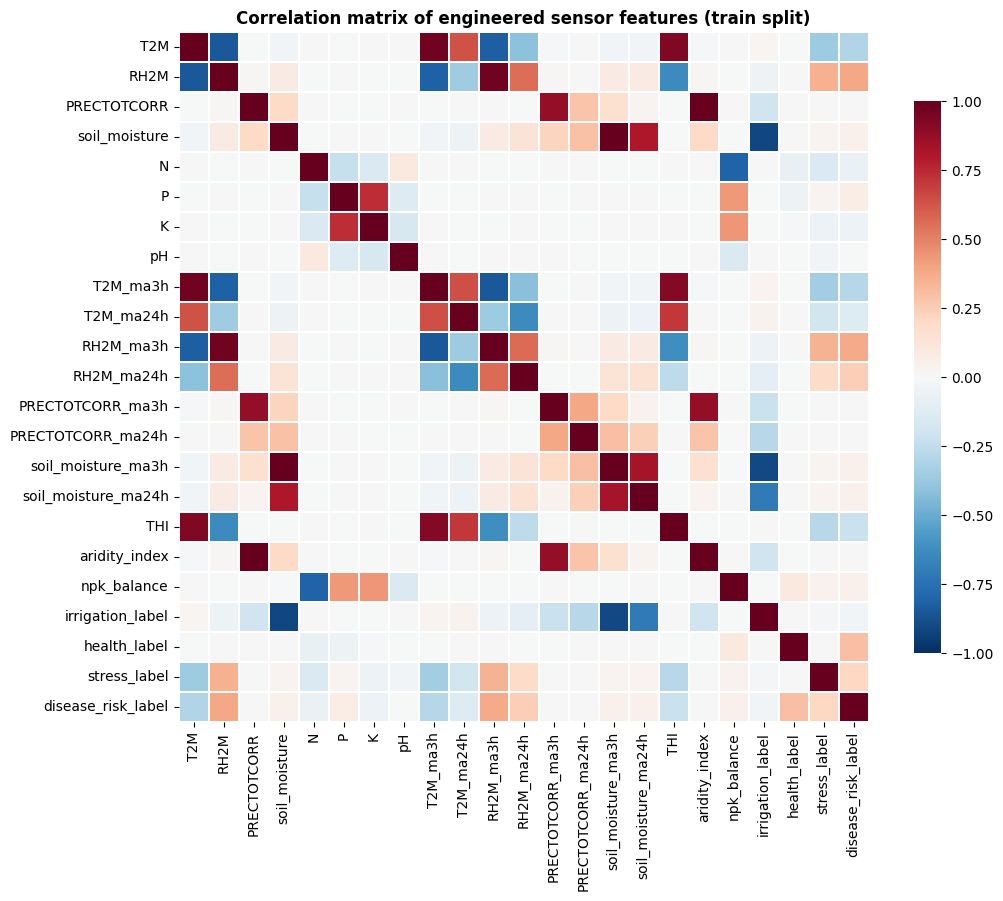

C:\Users\91979\AppData\Local\Temp\ipykernel_4752\1698716848.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sensor_df, x="location", y="T2M", ax=axes[0], palette="Set2")
C:\Users\91979\AppData\Local\Temp\ipykernel_4752\1698716848.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sensor_df, x="location", y="PRECTOTCORR", ax=axes[1], palette="Set2")


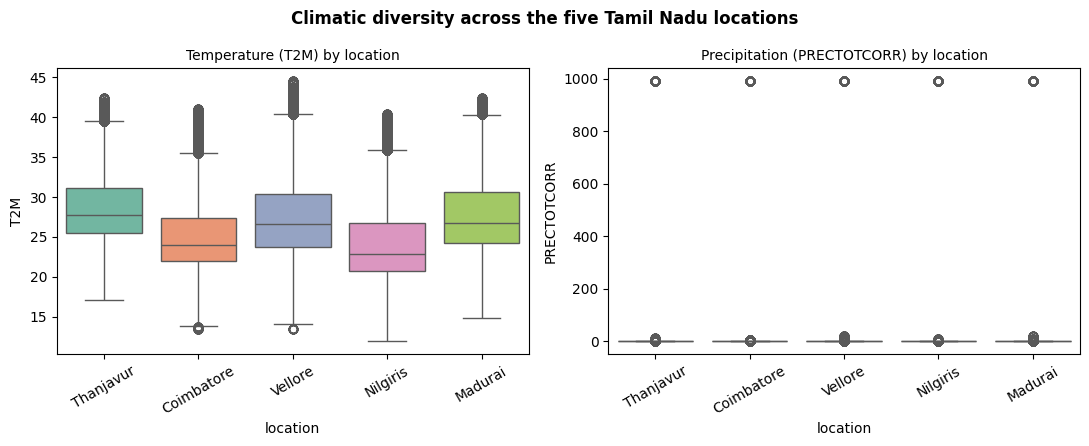

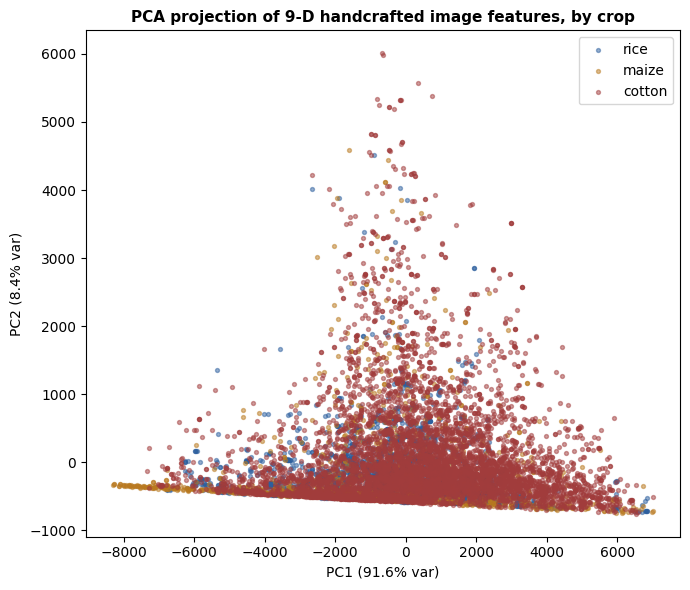

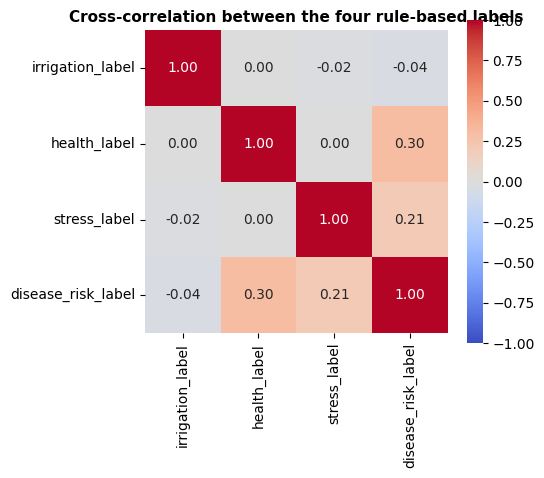

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA

# ============================================================
# CHART A — Correlation heatmap of engineered sensor features
# Goes in: Section IV-C (end), or new Section V-A2
# Shows the 27 engineered features aren't redundant/collinear
# ============================================================
# Assumes sensor_df is your final engineered dataframe (pre-windowing)
numeric_cols = sensor_df.select_dtypes(include=[np.number]).columns
corr = sensor_df[numeric_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix of engineered sensor features (train split)", fontsize=12, weight="bold")
plt.tight_layout()
plt.savefig("fig_feature_correlation.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# CHART B — Per-location climate diversity (boxplots)
# Goes in: Section IV-A (Data Acquisition), right after
# describing the 5 locations — PROVES they're agro-climatically distinct
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=sensor_df, x="location", y="T2M", ax=axes[0], palette="Set2")
axes[0].set_title("Temperature (T2M) by location", fontsize=10)
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=sensor_df, x="location", y="PRECTOTCORR", ax=axes[1], palette="Set2")
axes[1].set_title("Precipitation (PRECTOTCORR) by location", fontsize=10)
axes[1].tick_params(axis="x", rotation=30)

plt.suptitle("Climatic diversity across the five Tamil Nadu locations", fontsize=12, weight="bold")
plt.tight_layout()
plt.savefig("fig_location_climate_diversity.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# CHART C — PCA of the 9-D handcrafted image features, colored by crop
# Goes in: Section IV-D (end) or Section V-C
# Shows the handcrafted features actually separate crops/diseases —
# direct evidence supporting your "low-variance signal" claim
# ============================================================
# Uses hc_train (N, 9) and dislabel_train (N,) - the actual pipeline variable names
pca = PCA(n_components=2)
proj = pca.fit_transform(hc_train)  # fixed: was X_handcrafted_train (undefined)

plt.figure(figsize=(7, 6))
crops = ["rice", "maize", "cotton"]  # derive crop from dislabel_train folder name
crop_of = lambda lbl: "rice" if "rice" in lbl.lower() else ("maize" if "maize" in lbl.lower() or "corn" in lbl.lower() else "cotton")
colors_map = {"rice": "#2C5F9E", "maize": "#B9791F", "cotton": "#A13C3C"}
crop_arr = np.array([crop_of(l) for l in dislabel_train])  # fixed: was disease_labels_train (undefined)

for c in crops:
    mask = crop_arr == c
    plt.scatter(proj[mask, 0], proj[mask, 1], s=8, alpha=0.5, label=c, color=colors_map[c])

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("PCA projection of 9-D handcrafted image features, by crop", fontsize=11, weight="bold")
plt.legend()
plt.tight_layout()
plt.savefig("fig_handcrafted_pca.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# CHART D — Correlation between the 4 rule-based sensor labels
# Goes in: Section V-E (Implications) — directly supports your claim
# that "correlations are expected between soil-health and disease-risk heads"
# ============================================================
from sklearn.preprocessing import LabelEncoder

label_cols = ["irrigation_label", "health_label", "stress_label", "disease_risk_label"]  # fixed: matched to actual sensor_df column names
encoded = sensor_df[label_cols].apply(lambda col: LabelEncoder().fit_transform(col))
label_corr = encoded.corr()

plt.figure(figsize=(5.5, 4.8))
sns.heatmap(label_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Cross-correlation between the four rule-based labels", fontsize=11, weight="bold")
plt.tight_layout()
plt.savefig("fig_label_cross_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

Healthy sample : Healthy cotton/555.jpg
Diseased sample: American Bollworm on Cotton/Image_1.jpg


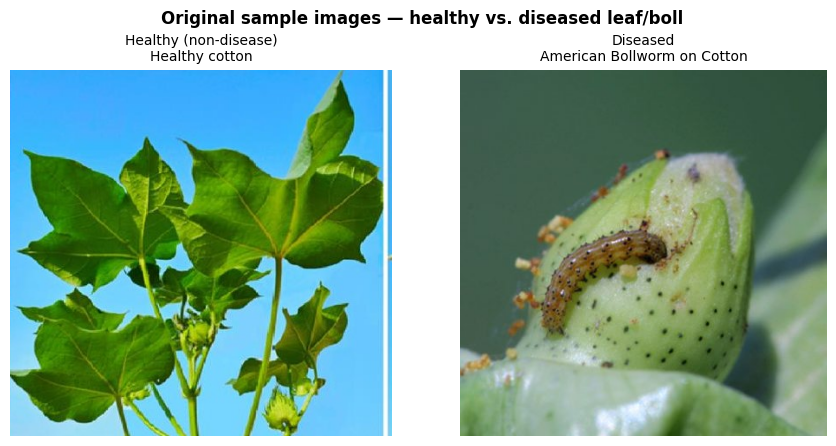

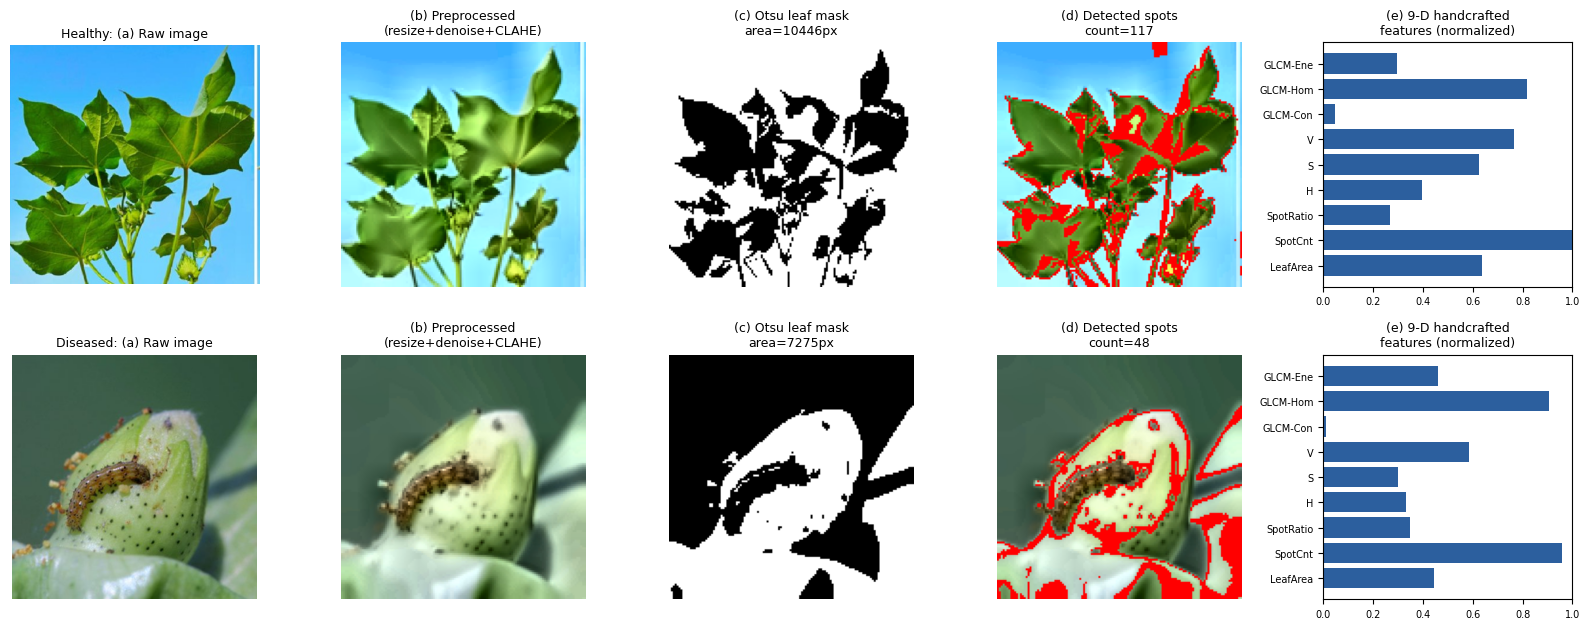

In [27]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import graycomatrix, graycoprops

# ----------------------------------------------------------------------
# 1. Locate one HEALTHY and one DISEASED sample image from the dataset
# ----------------------------------------------------------------------
all_classes = os.listdir(train_path)

healthy_classes = [c for c in all_classes if "healthy" in c.lower()]
disease_classes = [c for c in all_classes if "healthy" not in c.lower()]

healthy_class = healthy_classes[0]          # e.g. "Healthy Maize"
disease_class = disease_classes[0]          # swap index / hardcode a name
                                             # to pick a specific disease class

def get_sample_path(cls):
    folder = os.path.join(train_path, cls)
    fname = os.listdir(folder)[0]
    return os.path.join(folder, fname), fname

healthy_img_path, healthy_fname = get_sample_path(healthy_class)
disease_img_path, disease_fname = get_sample_path(disease_class)

print(f"Healthy sample : {healthy_class}/{healthy_fname}")
print(f"Diseased sample: {disease_class}/{disease_fname}")

# ----------------------------------------------------------------------
# 2. Preview the two RAW images side-by-side — original, before any
#    processing — this is the "healthy vs. diseased" comparison figure
# ----------------------------------------------------------------------
raw_healthy = np.array(Image.open(healthy_img_path).convert("RGB"))
raw_disease = np.array(Image.open(disease_img_path).convert("RGB"))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(raw_healthy)
axes[0].set_title(f"Healthy (non-disease)\n{healthy_class}", fontsize=10)
axes[0].axis("off")

axes[1].imshow(raw_disease)
axes[1].set_title(f"Diseased\n{disease_class}", fontsize=10)
axes[1].axis("off")

plt.suptitle("Original sample images — healthy vs. diseased leaf/boll",
             fontsize=12, weight="bold")
plt.tight_layout()
plt.savefig("fig_healthy_vs_diseased_raw.png", dpi=300, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# 3. Full Stage 3-R / Stage 4-R pipeline as a reusable function
#    (resize -> denoise -> CLAHE -> leaf mask -> spot detection -> GLCM)
# ----------------------------------------------------------------------
def preprocess_and_extract_features(raw_rgb, img_size=128):
    """Runs the exact preprocessing + handcrafted-feature pipeline and
    returns every intermediate artifact needed for the demo figure."""
    resized = cv2.resize(raw_rgb, (img_size, img_size), interpolation=cv2.INTER_AREA)

    # --- Denoise ---
    denoised = cv2.fastNlMeansDenoisingColored(
        resized, None, h=6, hColor=6, templateWindowSize=7, searchWindowSize=21
    )

    # --- CLAHE on the L channel of LAB ---
    lab = cv2.cvtColor(denoised, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    preprocessed = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2RGB)

    # --- Leaf mask (Otsu on grayscale) ---
    gray = cv2.cvtColor(preprocessed, cv2.COLOR_RGB2GRAY)
    _, leaf_mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    leaf_area = int(np.sum(leaf_mask > 0))

    # --- Spot detection: darkest 35th percentile of in-leaf V channel ---
    hsv = cv2.cvtColor(preprocessed, cv2.COLOR_RGB2HSV)
    v_channel = hsv[:, :, 2]
    in_leaf_v = v_channel[leaf_mask > 0]
    thresh_val = np.percentile(in_leaf_v, 35) if len(in_leaf_v) else 0
    spot_mask = ((v_channel < thresh_val) & (leaf_mask > 0)).astype(np.uint8) * 255
    n_labels, _ = cv2.connectedComponents(spot_mask)
    spot_count = n_labels - 1
    spot_area_ratio = float(np.sum(spot_mask > 0)) / max(leaf_area, 1)

    # --- Color means ---
    mean_h, mean_s, mean_v = hsv[:, :, 0].mean(), hsv[:, :, 1].mean(), hsv[:, :, 2].mean()

    # --- GLCM texture (contrast, homogeneity, energy) ---
    g8 = (gray // 32).astype(np.uint8)
    glcm = graycomatrix(g8, distances=[1], angles=[0], levels=8, symmetric=True, normed=True)
    contrast    = graycoprops(glcm, "contrast")[0, 0]
    homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
    energy      = graycoprops(glcm, "energy")[0, 0]

    features = np.array([
        leaf_area, spot_count, spot_area_ratio,
        mean_h, mean_s, mean_v,
        contrast, homogeneity, energy
    ])

    return {
        "preprocessed": preprocessed, "leaf_mask": leaf_mask,
        "spot_mask": spot_mask, "leaf_area": leaf_area,
        "spot_count": spot_count, "spot_area_ratio": spot_area_ratio,
        "features": features,
    }

healthy_result = preprocess_and_extract_features(raw_healthy)
disease_result = preprocess_and_extract_features(raw_disease)

# ----------------------------------------------------------------------
# 4. Plot the full 2-row x 5-column comparison figure
#    Row 1 = healthy sample, Row 2 = diseased sample
# ----------------------------------------------------------------------
feat_names = ["LeafArea", "SpotCnt", "SpotRatio", "H", "S", "V",
              "GLCM-Con", "GLCM-Hom", "GLCM-Ene"]

def normalize_features(f):
    return [f[0]/16384, f[1]/50, f[2], f[3]/180, f[4]/255, f[5]/255,
            f[6]/20, f[7], f[8]]

fig, axes = plt.subplots(2, 5, figsize=(16, 6.4))

for row, (label, raw_img, result) in enumerate([
    ("Healthy", raw_healthy, healthy_result),
    ("Diseased", raw_disease, disease_result),
]):
    axes[row, 0].imshow(raw_img)
    axes[row, 0].set_title(f"{label}: (a) Raw image", fontsize=9)
    axes[row, 0].axis("off")

    axes[row, 1].imshow(result["preprocessed"])
    axes[row, 1].set_title("(b) Preprocessed\n(resize+denoise+CLAHE)", fontsize=9)
    axes[row, 1].axis("off")

    axes[row, 2].imshow(result["leaf_mask"], cmap="gray")
    axes[row, 2].set_title(f"(c) Otsu leaf mask\narea={result['leaf_area']}px", fontsize=9)
    axes[row, 2].axis("off")

    overlay = result["preprocessed"].copy()
    overlay[result["spot_mask"] > 0] = [255, 0, 0]
    axes[row, 3].imshow(overlay)
    axes[row, 3].set_title(f"(d) Detected spots\ncount={result['spot_count']}", fontsize=9)
    axes[row, 3].axis("off")

    axes[row, 4].barh(feat_names, normalize_features(result["features"]), color="#2C5F9E")
    axes[row, 4].set_title("(e) 9-D handcrafted\nfeatures (normalized)", fontsize=9)
    axes[row, 4].set_xlim(0, 1)
    axes[row, 4].tick_params(labelsize=7)

plt.tight_layout()
plt.savefig("fig_healthy_vs_diseased_pipeline.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - climatic_stress_accuracy: 0.6480 - climatic_stress_loss: 0.7718 - crop_recommendation_accuracy: 0.4568 - crop_recommendation_loss: 1.8023 - disease_risk_accuracy: 0.7196 - disease_risk_loss: 0.5251 - irrigation_accuracy: 0.9746 - irrigation_loss: 0.1123 - loss: 3.9038 - soil_health_accuracy: 0.5788 - soil_health_loss: 0.6881 - val_climatic_stress_accuracy: 0.7955 - val_climatic_stress_loss: 0.5195 - val_crop_recommendation_accuracy: 0.7072 - val_crop_recommendation_loss: 0.6739 - val_disease_risk_accuracy: 0.7220 - val_disease_risk_loss: 0.5035 - val_irrigation_accuracy: 0.9931 - val_irrigation_loss: 0.0419 - val_loss: 2.4147 - val_soil_health_accuracy: 0.5832 - val_soil_health_loss: 0.6756
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - climatic_stress_accuracy: 0.8048 - climatic_stress_loss: 0.4533 - crop_recommendation_accuracy: 0.7315 - crop_recommendation_loss: 0.5256 - disease_risk_accuracy: 0.7451 - disease_risk_loss:

d:\PythonProjects\MTEI\.venv\lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


301/301 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - accuracy: 0.1402 - loss: 84.5111 - val_accuracy: 0.2947 - val_loss: 5.6925
Epoch 2/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.2140 - loss: 5.5766 - val_accuracy: 0.2806 - val_loss: 4.2307
Epoch 3/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.2456 - loss: 4.5541 - val_accuracy: 0.3180 - val_loss: 3.7896
Epoch 4/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.2637 - loss: 4.1073 - val_accuracy: 0.2830 - val_loss: 3.7024
Epoch 5/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 24s 78ms/step - accuracy: 0.2695 - loss: 3.9461 - val_accuracy: 0.2345 - val_loss: 6.3338
Epoch 6/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.2848 - loss: 3.6660 - val_accuracy: 0.3383 - val_loss: 3.7672
Epoch 7/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.3029 - loss: 3.3569 - val_accuracy: 0.3277 - val_loss: 2.8862
Epoch 8/8
301/301 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.3151 - loss: 3.3084 - val_accuracy: 0.2

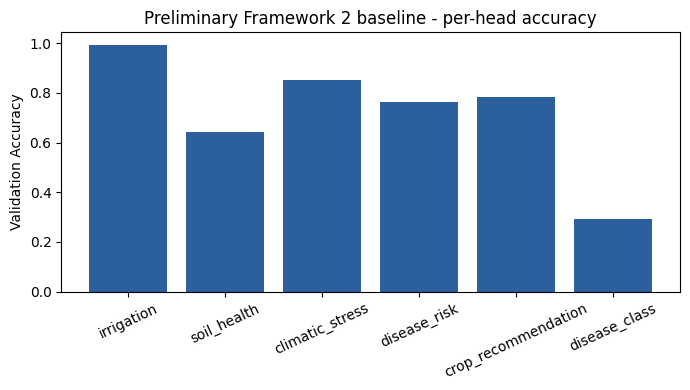

In [30]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd

# ============================================================
# FRAMEWORK 2 — Preliminary multi-task baseline
# Loads straight from the saved archive (robust regardless of
# what is still in memory) — matches the approach used in Tables 1-4.
# ============================================================
data = np.load("mtei_ready_dataset.npz", allow_pickle=True)

X_sensor_train = data["X_sensor_train"]
y_sensor_train = data["y_sensor_train"]          # shape (N, 4): irrigation, health, stress, disease_risk (already int-coded 0/1/2)
crop_onehot_train = data["crop_onehot_train"]    # one-hot (N, 22)

X_sensor_val = data["X_sensor_val"]
y_sensor_val = data["y_sensor_val"]
crop_onehot_val = data["crop_onehot_val"]

n_irr, n_health, n_stress, n_risk = 3, 2, 3, 2     # from label_irrigation/label_soil_health/etc. return ranges
n_crop = crop_onehot_train.shape[1]
crop_train_int = np.argmax(crop_onehot_train, axis=1)
crop_val_int = np.argmax(crop_onehot_val, axis=1)

# --- Subsample for a quick baseline run (751k windows is large for a first pass) ---
SUBSAMPLE_N = 60_000
rng = np.random.default_rng(42)
idx = rng.choice(len(X_sensor_train), size=min(SUBSAMPLE_N, len(X_sensor_train)), replace=False)
X_sub = X_sensor_train[idx]
y_sub = y_sensor_train[idx]
crop_sub = crop_train_int[idx]

# --- Multi-task GRU ---
sensor_input = layers.Input(shape=X_sensor_train.shape[1:], name="sensor_window")
x = layers.GRU(64, return_sequences=True)(sensor_input)
x = layers.GRU(32)(x)
shared = layers.Dense(32, activation="relu")(x)

out_irr    = layers.Dense(n_irr,   activation="softmax", name="irrigation")(shared)
out_health = layers.Dense(n_health,activation="softmax", name="soil_health")(shared)
out_stress = layers.Dense(n_stress,activation="softmax", name="climatic_stress")(shared)
out_risk   = layers.Dense(n_risk,  activation="softmax", name="disease_risk")(shared)
out_crop   = layers.Dense(n_crop,  activation="softmax", name="crop_recommendation")(shared)

gru_model = Model(sensor_input, [out_irr, out_health, out_stress, out_risk, out_crop])

gru_model.compile(
    optimizer="adam",
    loss=["sparse_categorical_crossentropy"] * 5,
    metrics=["accuracy"] * 5,   # <-- was ["accuracy"], now matches the 5 outputs
)

gru_model.fit(
    X_sub,
    [y_sub[:, 0], y_sub[:, 1], y_sub[:, 2], y_sub[:, 3], crop_sub],
    validation_data=(X_sensor_val,
        [y_sensor_val[:, 0], y_sensor_val[:, 1], y_sensor_val[:, 2], y_sensor_val[:, 3], crop_val_int]),
    epochs=5, batch_size=256, verbose=1,
)

preds = gru_model.predict(X_sensor_val)
head_names = ["irrigation", "soil_health", "climatic_stress", "disease_risk", "crop_recommendation"]
y_trues = [y_sensor_val[:, 0], y_sensor_val[:, 1], y_sensor_val[:, 2], y_sensor_val[:, 3], crop_val_int]

rows = []
for name, y_true, pred in zip(head_names, y_trues, preds):
    y_pred = np.argmax(pred, axis=1)
    rows.append({"Task": name, "Accuracy": round(accuracy_score(y_true, y_pred), 3),
                 "Macro-F1": round(f1_score(y_true, y_pred, average="macro"), 3)})
sensor_results_df = pd.DataFrame(rows)
print(sensor_results_df)

# --- Image branch (disease classification) ---
X_images_train, X_handcrafted_train, disease_label_train = data["X_images_train"], data["X_handcrafted_train"], data["disease_label_train"]
X_images_val, X_handcrafted_val, disease_label_val = data["X_images_val"], data["X_handcrafted_val"], data["disease_label_val"]

le_disease = LabelEncoder()
y_disease_train = le_disease.fit_transform(disease_label_train)
y_disease_val = le_disease.transform(disease_label_val)
n_disease = len(le_disease.classes_)

img_input = layers.Input(shape=(128, 128, 3))
feat_input = layers.Input(shape=(9,))
c = layers.Conv2D(16, 3, activation="relu")(img_input)
c = layers.MaxPooling2D()(c)
c = layers.Conv2D(32, 3, activation="relu")(c)
c = layers.MaxPooling2D()(c)
c = layers.GlobalAveragePooling2D()(c)
f = layers.Dense(16, activation="relu")(feat_input)
merged = layers.Concatenate()([c, f])
merged = layers.Dense(64, activation="relu")(merged)
out_disease = layers.Dense(n_disease, activation="softmax")(merged)

cnn_model = Model([img_input, feat_input], out_disease)
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
import gc

# Free memory from the large sensor-path arrays before training the CNN
del X_sensor_train, X_sub, X_sensor_val
gc.collect()

# Stream images in batches instead of handing Keras one giant array at once
# (avoids the MemoryError from converting the whole (9615,128,128,3) array to a tensor)
def make_image_dataset(images, handcrafted, labels, batch_size=32, shuffle=True):
    def gen():
        for img, feat, lab in zip(images, handcrafted, labels):
            yield (img, feat), lab
    output_signature = (
        (tf.TensorSpec(shape=(128, 128, 3), dtype=tf.float32),
         tf.TensorSpec(shape=(9,), dtype=tf.float32)),
        tf.TensorSpec(shape=(), dtype=tf.int64),
    )
    ds = tf.data.Dataset.from_generator(gen, output_signature=output_signature)
    if shuffle:
        ds = ds.shuffle(2000, seed=42)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_image_dataset(X_images_train, X_handcrafted_train, y_disease_train, batch_size=32, shuffle=True)
val_ds   = make_image_dataset(X_images_val,   X_handcrafted_val,   y_disease_val,   batch_size=32, shuffle=False)

cnn_model.fit(train_ds, validation_data=val_ds, epochs=8, verbose=1)

disease_pred = np.argmax(cnn_model.predict(val_ds), axis=1)
image_results_df = pd.DataFrame([{
    "Task": "disease_class",
    "Accuracy": round(accuracy_score(y_disease_val, disease_pred), 3),
    "Macro-F1": round(f1_score(y_disease_val, disease_pred, average="macro"), 3),
}])

final_results_df = pd.concat([sensor_results_df, image_results_df], ignore_index=True)
print(final_results_df)
final_results_df.to_csv("framework2_baseline_results.csv", index=False)

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.bar(final_results_df["Task"], final_results_df["Accuracy"], color="#2C5F9E")
plt.ylabel("Validation Accuracy")
plt.xticks(rotation=25)
plt.title("Preliminary Framework 2 baseline - per-head accuracy")
plt.tight_layout()
plt.savefig("fig_framework2_baseline_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()


## Qualitative Validation of the Disease-Risk Rule

In [31]:
# ============================================================
# QUALITATIVE / INTERNAL-CONSISTENCY VALIDATION of the disease-risk rule
# Checks whether "At Risk" rows actually match the classic weather-driven
# fungal-favorable pattern (elevated RH + in-range T + active rain) that
# the rule itself is built on. This is an INTERNAL CONSISTENCY check, not
# an expert/agronomic validation - state that distinction in the paper.
# ============================================================
import pandas as pd

at_risk_sample = sensor_df[sensor_df["disease_risk_label"] == 1].sample(
    n=25, random_state=42
)[["crop", "location", "T2M", "RH2M", "PRECTOTCORR", "K", "pH", "disease_risk_label"]].copy()

crop_stats_df = sensor_df.groupby("crop")[["T2M", "RH2M", "K", "pH"]].agg(["mean", "std"])

def annotate(row):
    c = row["crop"]
    t_mean, t_std = crop_stats_df.loc[c, ("T2M", "mean")], crop_stats_df.loc[c, ("T2M", "std")]
    rh_mean, rh_std = crop_stats_df.loc[c, ("RH2M", "mean")], crop_stats_df.loc[c, ("RH2M", "std")]
    row["T_in_range"] = abs(row["T2M"] - t_mean) < t_std
    row["RH_elevated"] = row["RH2M"] > rh_mean + rh_std
    row["rain_active"] = row["PRECTOTCORR"] > 0
    return row

at_risk_sample = at_risk_sample.apply(annotate, axis=1)
print(at_risk_sample.to_string())

agreement_rate = (
    at_risk_sample["RH_elevated"] & at_risk_sample["T_in_range"] & at_risk_sample["rain_active"]
).mean()
print(f"\nFraction of sampled 'At Risk' rows matching the classic weather-driven "
      f"fungal-favorable pattern (elevated RH + in-range T + active rain): {agreement_rate:.0%}")

at_risk_sample.to_csv("disease_risk_qualitative_validation.csv", index=False)


                crop    location    T2M   RH2M  PRECTOTCORR           K        pH  disease_risk_label  T_in_range  RH_elevated  rain_active
1067154     chickpea  Coimbatore  22.08  89.95         0.24   75.389363  6.450783                   1        True        False         True
1339702       lentil  Coimbatore  21.52  95.78         0.08   21.000347  7.155495                   1        True         True         True
2178022         jute    Nilgiris  22.25  92.13         0.02   41.107838  7.349421                   1        True        False         True
1447119        mango  Coimbatore  27.29  68.06         0.05   28.838973  4.741326                   1        True        False         True
3177896       lentil     Madurai  27.54  71.27         0.02   18.969512  7.262342                   1        True        False         True
2971049       coffee     Madurai  25.17  92.18         0.08   30.045806  6.658858                   1        True        False         True
1362152       lentil